In [21]:

%pip install wordcloud


Note: you may need to restart the kernel to use updated packages.


Total Sentences: 362

AGGREGATE SUMMARY:

In its simplest form,
developmental research can be either
 the study of the process and impact of specific instructional
design and development efforts; or
 a situation in which someone is performing instructional design, development, or evaluation activities and studying the
process at the same time; or
 the study of the instructional design, development, and evaluation process as a whole or of particular process components. While instructional development typically builds on previous research, developmental research attempts to produce the
models and principles that guide the design, development, and
evaluation processes. Cronbach’s alpha is regularly adopted in studies in science education: it was referred to in 69 different papers published in 4 leading science education journals in a single year (2015)—usually as a measure of reliability. The Use of Cronbach’s Alpha in Science Education Studies
It is common to see the reliability of in

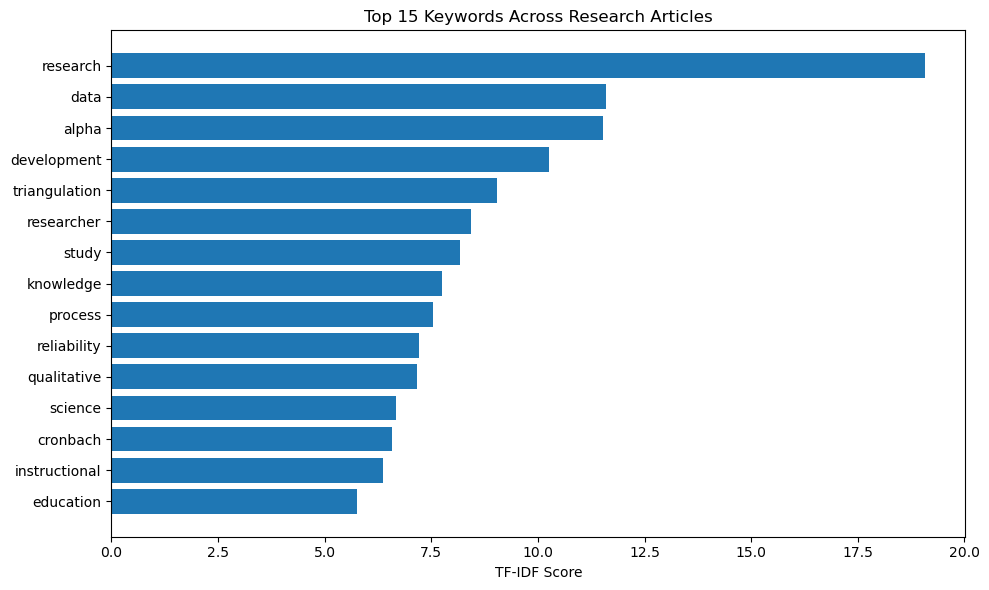


Question 3.4 Completed Successfully!


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk

from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

if 'df_articles' not in globals():
    df_articles = pd.read_csv('cleaned_research_corpus.csv')

df_articles = df_articles.sort_values(
    'Article'
).reset_index(drop=True)

remaining_articles = df_articles.iloc[1:]

sentences = []
sources = []

for _, row in remaining_articles.iterrows():

    article_sentences = sent_tokenize(str(row['Content']))

    valid_sentences = [
        sentence.strip()
        for sentence in article_sentences
        if len(sentence.split()) >= 5
    ]

    for sentence in valid_sentences[:100]:
        sentences.append(sentence)
        sources.append(row['Article'])

print("Total Sentences:", len(sentences))

if len(sentences) < 2:
    raise ValueError("Not enough sentences for summarisation.")

tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=1000
)

matrix = tfidf.fit_transform(sentences)

lsa = TruncatedSVD(
    n_components=min(3, min(matrix.shape) - 1),
    random_state=42
)

lsa_matrix = lsa.fit_transform(matrix)

scores = np.linalg.norm(
    lsa_matrix,
    axis=1
)

top_indices = np.argsort(scores)[-10:]
top_indices = sorted(top_indices)

summary = ' '.join(
    sentences[i] for i in top_indices
)

print("\nAGGREGATE SUMMARY:\n")
print(summary)

feature_names = tfidf.get_feature_names_out()

keyword_scores = np.asarray(
    matrix.sum(axis=0)
).ravel()

top_keywords = pd.DataFrame({
    'Keyword': feature_names,
    'Score': keyword_scores
}).sort_values(
    'Score', ascending=False
).head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_keywords['Keyword'][::-1],
    top_keywords['Score'][::-1]
)

plt.title('Top 15 Keywords Across Research Articles')
plt.xlabel('TF-IDF Score')
plt.tight_layout()
plt.show()

with open(
    'aggregate_research_summary.txt',
    'w',
    encoding='utf-8'
) as file:
    file.write(summary)

print("\nQuestion 3.4 Completed Successfully!")
